# Exercise 1 (10 points)

In this exercise, we will practice how to properly format code. You are given a simple but poorly formatted Python code snippet that performs some common data science tasks (loading data, cleaning, and basic analysis). Your task is to refactor the code to improve readability, organization, and adhere to Python's PEP8 formatting guidelines.

```
import pandas as pd 
import numpy as np

data=pd.read_csv('credit_risk_dataset.csv')
# drop rows with missing values
data=data.dropna()

cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
def converting_datatypes(df, cat_cols, df_train=False):
    
    for col in cat_cols:
        df[col] = df[col].astype('category')
    
    df['person_age'] = df['person_age'].astype('int32')
    df['cb_person_cred_hist_length'] = df['cb_person_cred_hist_length'].astype('int32') 
    
    if df_train==True:

        df['loan_status'] = df['loan_status'].astype('int8')
        
    return df
        
data = converting_datatypes(data, cat_cols, df_train=True)

X=data.drop('loan_status',axis=1)
y=data['loan_status']

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

from sklearn.ensemble import HistGradientBoostingClassifier
hg=HistGradientBoostingClassifier(n_estimators=100, categorical_features='from_dtype')
hg.fit(X_train,y_train)
print('Train accuracy:',hg.score(X_train,y_train))
print('Test accuracy:',hg.score(X_test,y_test))
```

In [17]:
import pandas as pd 
import numpy as np

data=pd.read_csv('credit_risk_dataset.csv')
# drop rows with missing values
data=data.dropna()

cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
def converting_datatypes(df, cat_cols, df_train=False):
    
    for col in cat_cols:
        df[col] = df[col].astype('category')
    
    df['person_age'] = df['person_age'].astype('int32')
    df['cb_person_cred_hist_length'] = df['cb_person_cred_hist_length'].astype('int32') 
    
    if df_train==True:

        df['loan_status'] = df['loan_status'].astype('int8')
        
    return df
        
data = converting_datatypes(data, cat_cols, df_train=True)

X=data.drop('loan_status',axis=1)
y=data['loan_status']

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

from sklearn.ensemble import HistGradientBoostingClassifier
hg=HistGradientBoostingClassifier(max_iter=100, categorical_features='from_dtype')
hg.fit(X_train,y_train)
print('Train accuracy:',hg.score(X_train,y_train))
print('Test accuracy:',hg.score(X_test,y_test))


Train accuracy: 0.9453257507732216
Test accuracy: 0.9326117318435754


In [18]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier


def convert_data_types(df, categorical_cols, include_target=False):
    """
    Convert DataFrame columns to appropriate data types.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe to convert
    categorical_cols : list
        List of column names to convert to category dtype
    include_target : bool, default=False
        Whether to convert 'loan_status' to int8 (for training data)

    Returns
    -------
    pd.DataFrame
        DataFrame with converted data types
    """
    # Convert categorical columns
    for col in categorical_cols:
        df[col] = df[col].astype('category')

    # Convert numeric columns
    df['person_age'] = df['person_age'].astype('int32')
    df['cb_person_cred_hist_length'] = (
        df['cb_person_cred_hist_length'].astype('int32')
    )

    # Convert target variable if this is training data
    if include_target:
        df['loan_status'] = df['loan_status'].astype('int8')

    return df


# Load and preprocess data
data = pd.read_csv('credit_risk_dataset.csv')
data = data.dropna()

# Define categorical columns
CATEGORICAL_COLS = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

# Convert data types
data = convert_data_types(data, CATEGORICAL_COLS, include_target=True)

# Separate features and target
X = data.drop('loan_status', axis=1)
y = data['loan_status']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Train HistGradientBoosting model
model = HistGradientBoostingClassifier(
    max_iter=100,
    categorical_features='from_dtype'
)
model.fit(X_train, y_train)

# Evaluate model
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print(f'Train accuracy: {train_accuracy:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')


Train accuracy: 0.9419
Test accuracy: 0.9299


# Exercise 2

In this exercise, we will practice data visualiation with the `credit_risk_dataset.csv` data file.

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`.

In [19]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




### Exercise 2(b) (2 points)

Read the `credit_risk_dataset.csv` data file and create a data frame called `credit`.

In [20]:

credit = pd.read_csv("credit_risk_dataset.csv")
credit.head()


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### Exercise 2(c) (4 points)

Create a histogram of `person_income`. Color the distribution based on `loan_status`. Comment on the shape of the distributions.

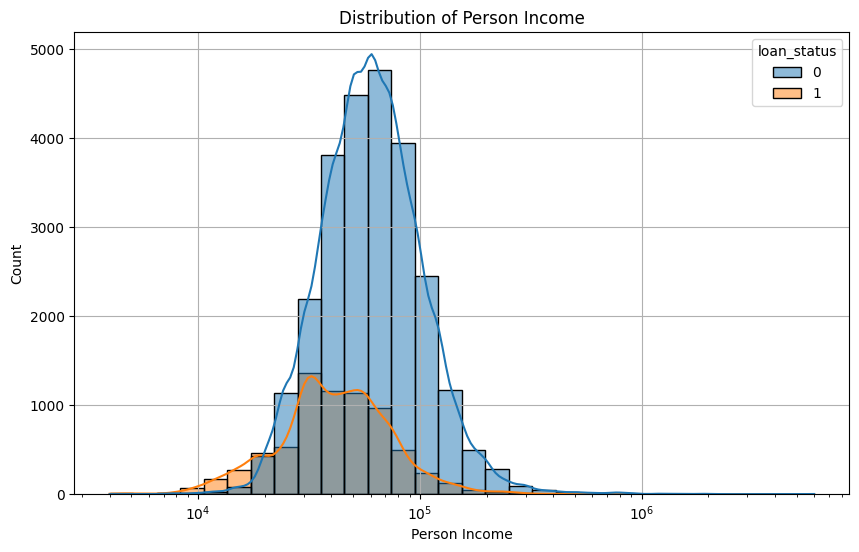

In [22]:

fig, ax = plt.subplots(figsize=(10,6))

sns.histplot(data=credit, x='person_income', hue='loan_status', bins=30, kde=True, ax=ax, log_scale=True)
ax.set_title('Distribution of Person Income')
ax.set_xlabel('Person Income')
ax.set_ylabel('Count')
ax.grid(True)
plt.show()




From the above chart, we observe that the distribution of `person_income` is right-skewed.


### Exercise 2(d) (5 points)

Create a side-by-side boxplot of `loan_int_rate` based on `loan_grade`. Describe the chart.

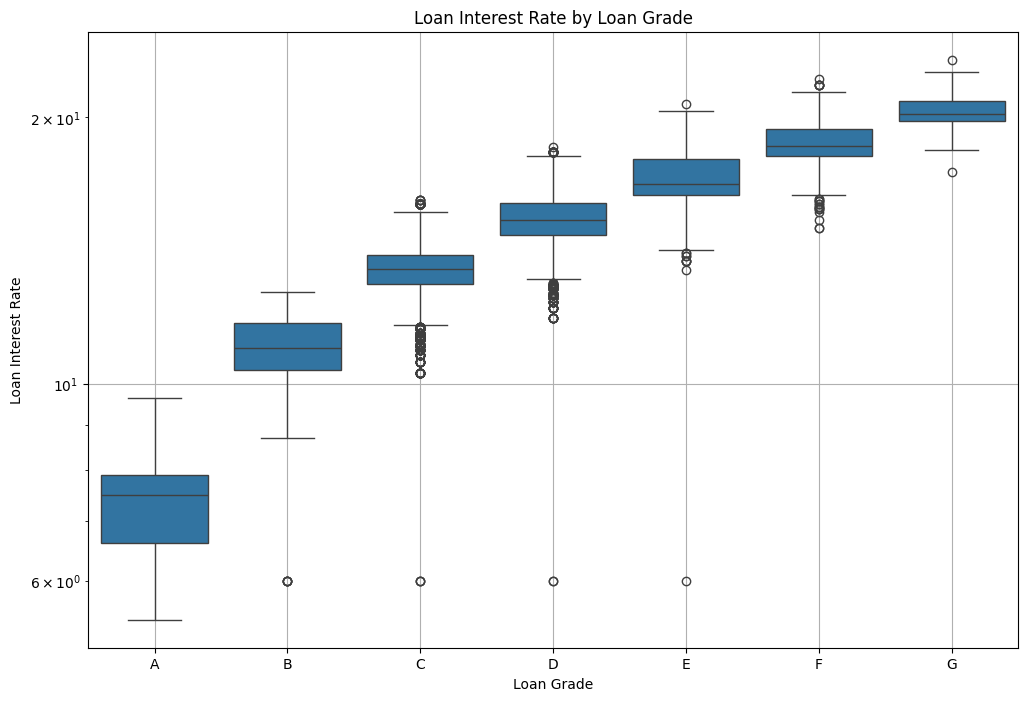

In [23]:

fig, ax = plt.subplots(figsize=(12, 8))

sns.boxplot(data=credit, x='loan_grade', y='loan_int_rate', ax=ax, log_scale=True, order=["A", "B", "C", "D", "E", "F", "G"])
ax.set_title('Loan Interest Rate by Loan Grade')
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Loan Interest Rate')
ax.grid(True)
plt.show()




From the chart, we can see that loan interest rates generally increase from loan grade A to loan grade G.


### Exercise 2(e) (10 points)

Is there a realtionship between `person_home_ownership`, `loan_intent`, and `loan_status`? Create a heatmap that shows the average `loan_status` based on `person_home_ownership` and `loan_intent`. Describe the chart.

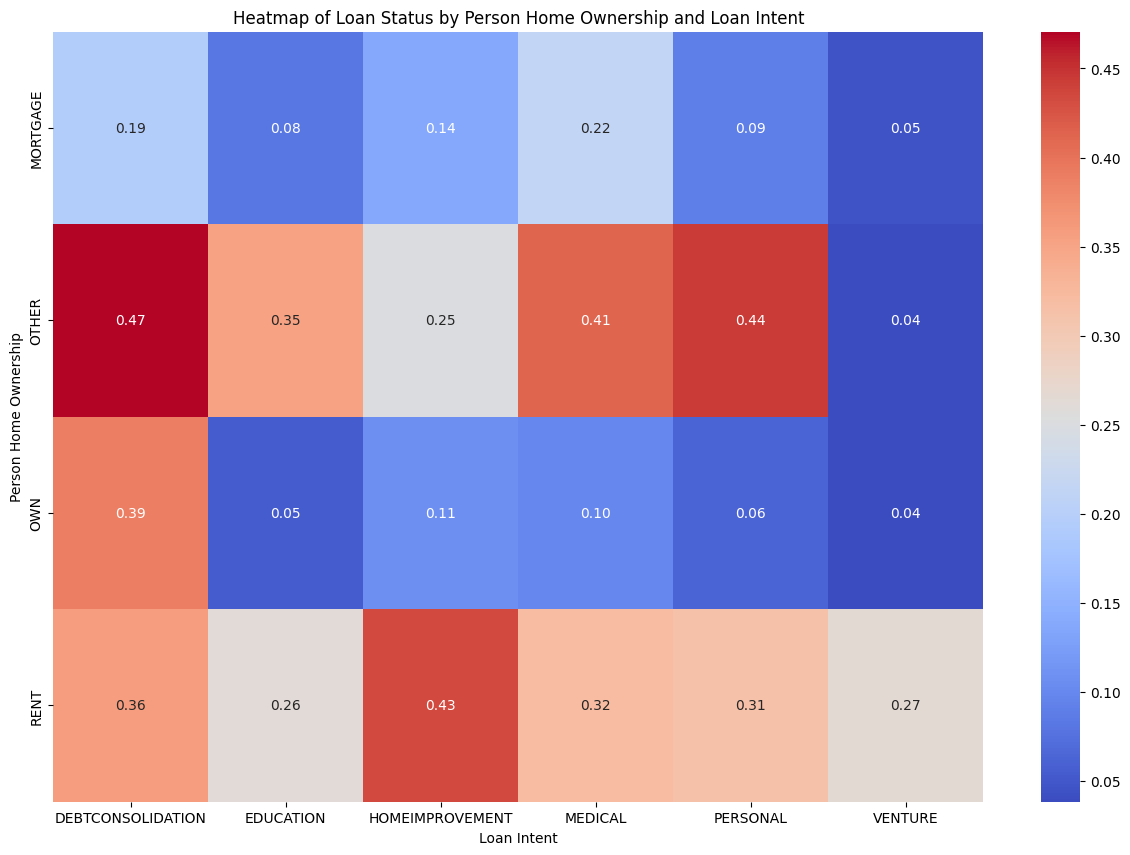

In [25]:

fig, ax = plt.subplots(figsize=(15, 10))

# Defining the categorical features
cat_features_1 = "person_home_ownership"
cat_features_2 = "loan_intent"
score = "loan_status"

# Creating the pivot table
pivot_table = credit.pivot_table(
    index=cat_features_1,
    columns=cat_features_2,
    values=score,
    aggfunc='mean'
)

# Plot the heatmap
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)

ax.set_title('Heatmap of Loan Status by Person Home Ownership and Loan Intent')
ax.set_xlabel('Loan Intent')
ax.set_ylabel('Person Home Ownership')

plt.show()



From the chart, I noticed two things:

- People with `person_home_ownership` = OTHER have the highest likelihood of defaulting.
- People with `person_home_ownership` = RENT have the second-highest likelihood of defaulting.


# Exercise 3 (10 points)

In this exercise, we will practice import formatting (Section 6.2 of Chapter 6).

### Exercise 3(a) (5 points)

The import block below grew organically and does not follow PEP8. Rewrite it so that:

- imports are grouped as (1) standard library, (2) third-party libraries, with a blank line between groups,
- imports are sorted alphabetically within each group (`import x` statements before `from x import y` statements),
- there is only one import per module line (for example, `import sys, os` must be split), and
- repeated imports from the same module are merged into a single line.


In [28]:
import time
from sklearn.metrics import accuracy_score

import sys, os
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score

In [27]:
import time
from sklearn.metrics import accuracy_score

import sys, os
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, f1_score

In [26]:

import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
from sklearn.model_selection import train_test_split


### Exercise 3(b) (5 points)

Name two cases where reordering imports (for example, with `isort`) is **not** behavior-preserving. How can you tell `isort` to leave a line alone?



Two cases where reordering imports changes behavior:

- **Order-dependent imports.** Setting the matplotlib backend requires `matplotlib.use("Agg")` to run before `matplotlib.pyplot` is imported, sorting alphabetically can move it after.
- **Registration (side-effect) imports.** Some libraries are imported only for the side effect (e.g., registering a plugin or an accessor). A linter may flag them as unused and offer to delete them.

To make `isort` skip a line, add `# isort: skip` to that line (or wrap the block in `# isort: off` / `# isort: on`)

